# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Sandi Suryo Nugroho | 5054251020 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Set random seed agar hasil dapat direproduksi
torch.manual_seed(42)
np.random.seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('Churn_Modelling.csv')
display(df.head())

print("--- Informasi Dataset ---")
df.info()

print("\n--- Statistik Deskriptif ---")
display(df.describe())

print("\n--- Jumlah Missing Value ---")
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

--- Statistik Deskriptif ---


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



--- Jumlah Missing Value ---
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


C:\Users\Axioo Pongo\AppData\Local\Temp\ipykernel_7160\3061483973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Exited', palette='viridis')


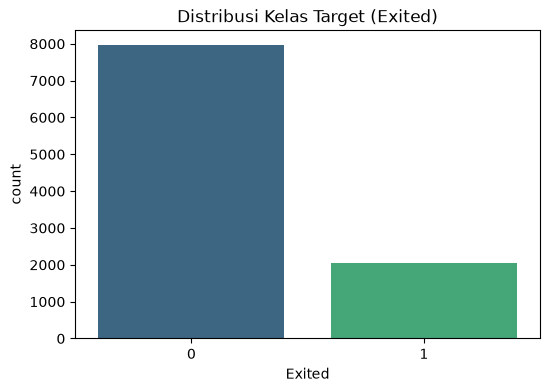

In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Exited', palette='viridis')
plt.title('Distribusi Kelas Target (Exited)')
plt.show()

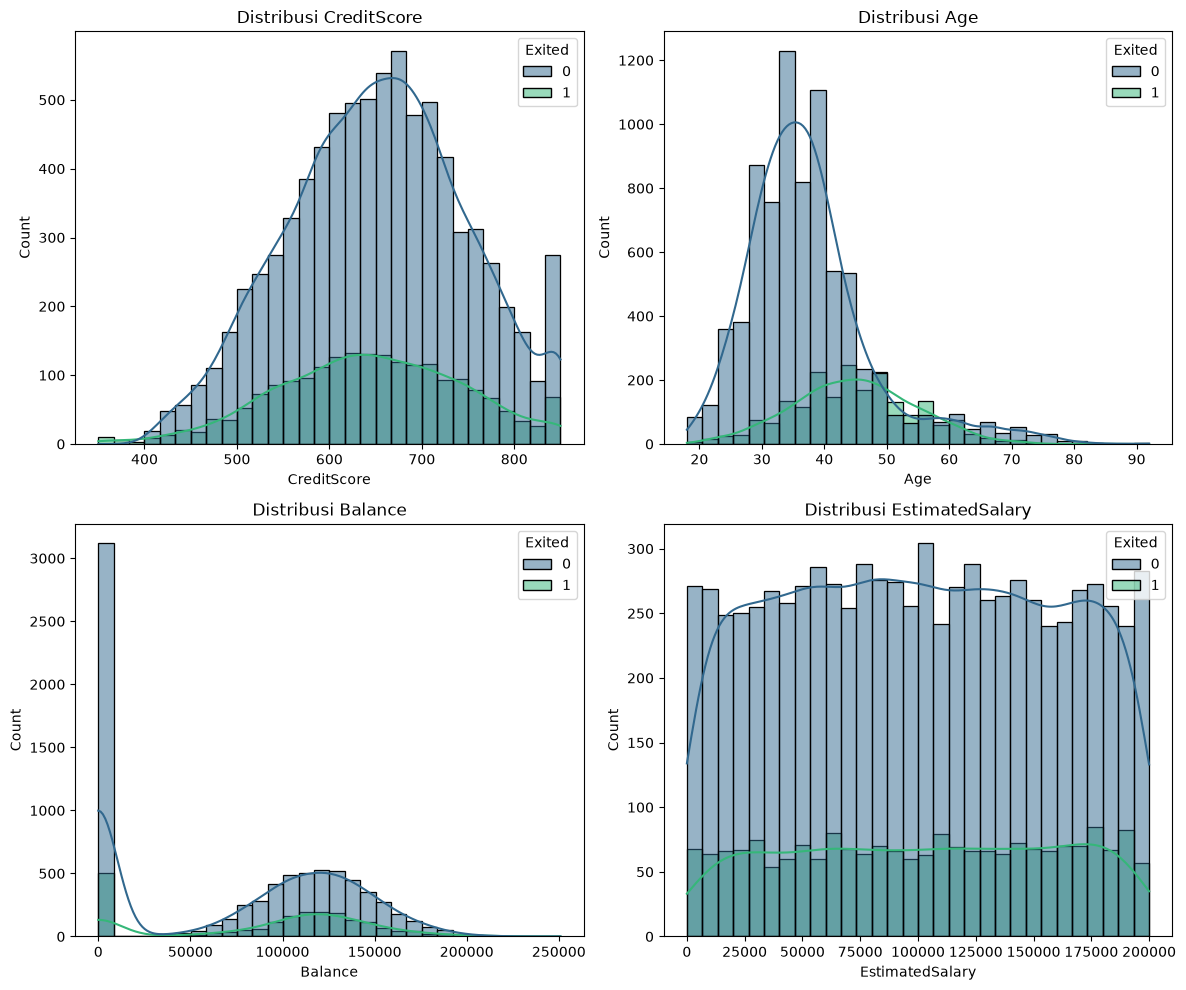

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
num_features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, col in enumerate(num_features):
    sns.histplot(data=df, x=col, hue='Exited', kde=True, ax=axes[i//2, i%2], bins=30, palette='viridis')
    axes[i//2, i%2].set_title(f'Distribusi {col}')

plt.tight_layout()
plt.show()

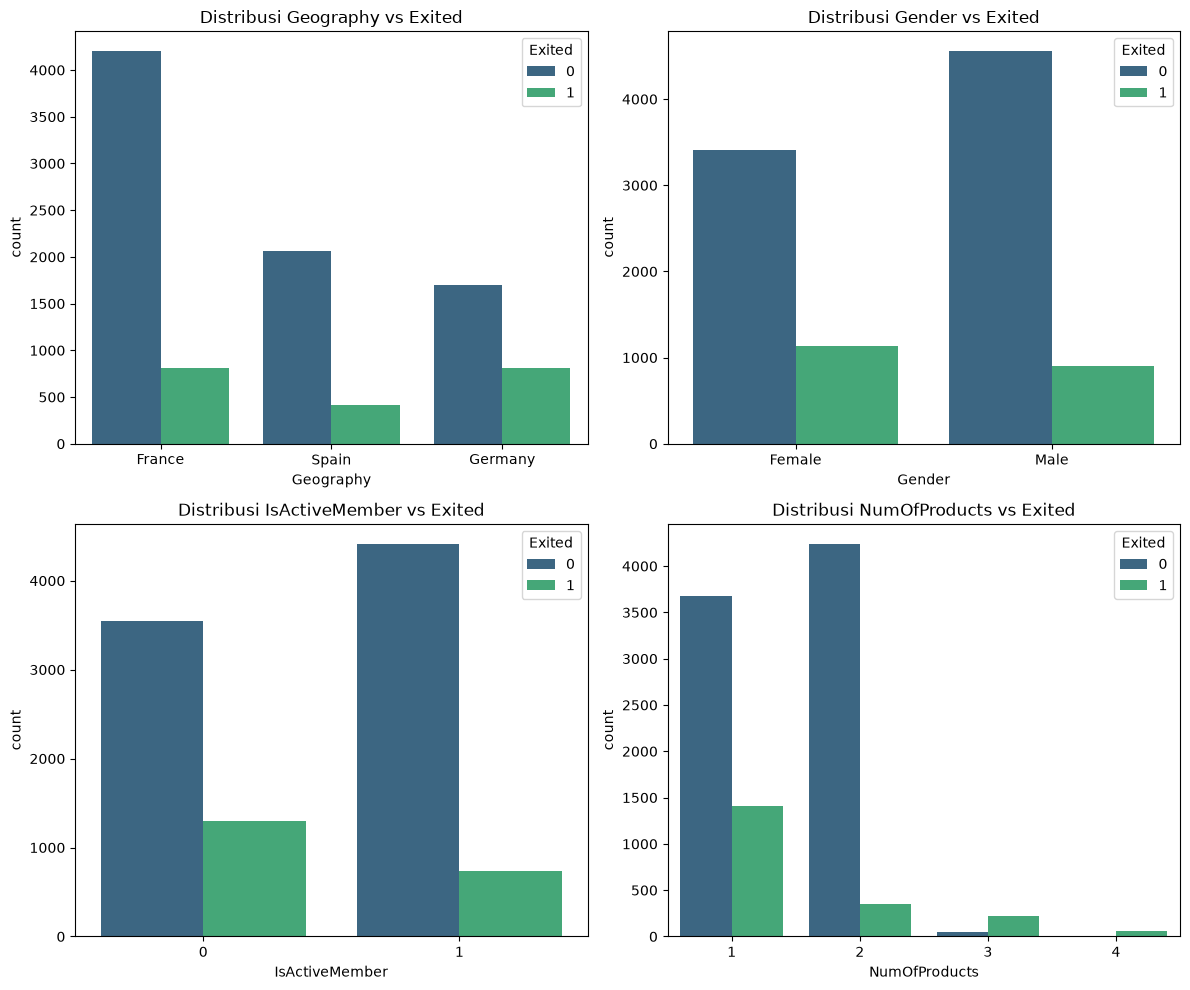

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
cat_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, col in enumerate(cat_features):
    sns.countplot(data=df, x=col, hue='Exited', ax=axes[i//2, i%2], palette='viridis')
    axes[i//2, i%2].set_title(f'Distribusi {col} vs Exited')

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [6]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
# Drop kolom identitas karena tidak memiliki power prediktif untuk machine learning
df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df_clean.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']

# Split 70% Train, 30% sisa (Val + Test) dengan stratify
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# Split 30% sisa menjadi 15% Validation dan 15% Test
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print(f"Ukuran Train: {X_train.shape}")
print(f"Ukuran Val: {X_val.shape}")
print(f"Ukuran Test: {X_test.shape}")

Ukuran Train: (7000, 10)
Ukuran Val: (1500, 10)
Ukuran Test: (1500, 10)


In [8]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
# Definisi kategori kolom
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
categorical_nominal = ['Geography']
categorical_binary = ['Gender'] # HasCrCard dan IsActiveMember sudah dalam bentuk 0/1

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat_nom', OneHotEncoder(drop='first', sparse_output=False), categorical_nominal),
        ('cat_bin', OrdinalEncoder(), categorical_binary)
    ],
    remainder='passthrough' # Biarkan HasCrCard dan IsActiveMember apa adanya
)

# Fit pada train, transform pada semuanya
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [9]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

# Ubah X menjadi float32
X_train_t = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_t = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_t = torch.tensor(X_test_processed, dtype=torch.float32)

# Ubah y menjadi (N, 1) float32
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# Buat DataLoader
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [10]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_processed, y_train)

lr_preds = lr_model.predict(X_test_processed)
lr_probs = lr_model.predict_proba(X_test_processed)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [11]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).
class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

input_dim = X_train_t.shape[1]
model_simple = SimpleANN(input_dim)

print(model_simple)
print(f"Total Parameters: {sum(p.numel() for p in model_simple.parameters())}")

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total Parameters: 209


In [12]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.
def train_model(model, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, epochs=50, lr=0.001, pos_weight=None):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

        # Evaluasi
        model.eval()
        with torch.no_grad():
            out_train = model(X_train_t)
            loss_train = criterion(out_train, y_train_t).item()
            acc_train = ((torch.sigmoid(out_train) >= 0.5) == y_train_t).float().mean().item()

            out_val = model(X_val_t)
            loss_val = criterion(out_val, y_val_t).item()
            acc_val = ((torch.sigmoid(out_val) >= 0.5) == y_val_t).float().mean().item()

        history['train_loss'].append(loss_train)
        history['val_loss'].append(loss_val)
        history['train_acc'].append(acc_train)
        history['val_acc'].append(acc_val)

    return history

history_simple = train_model(model_simple, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)

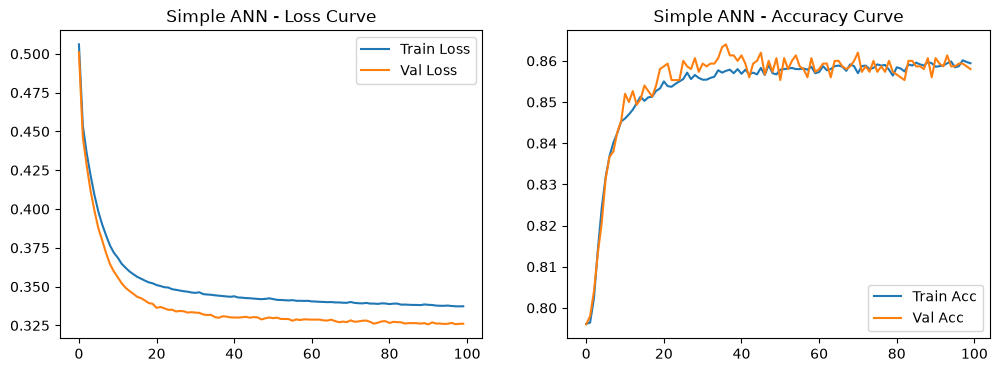

In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    axes[0].plot(history['train_loss'], label='Train Loss')
    axes[0].plot(history['val_loss'], label='Val Loss')
    axes[0].set_title(f'{title} - Loss Curve')
    axes[0].legend()

    axes[1].plot(history['train_acc'], label='Train Acc')
    axes[1].plot(history['val_acc'], label='Val Acc')
    axes[1].set_title(f'{title} - Accuracy Curve')
    axes[1].legend()
    plt.show()

plot_history(history_simple, "Simple ANN")

In [14]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.
model_simple.eval()
with torch.no_grad():
    simple_logits = model_simple(X_test_t)
    simple_probs = torch.sigmoid(simple_logits).numpy().flatten()
    simple_preds = (simple_probs >= 0.5).astype(int)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [15]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.
class DeepANN(nn.Module):
    def __init__(self, input_dim):
        super(DeepANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

model_deep = DeepANN(input_dim)
print(model_deep)
print(f"Total Parameters: {sum(p.numel() for p in model_deep.parameters())}")

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total Parameters: 929


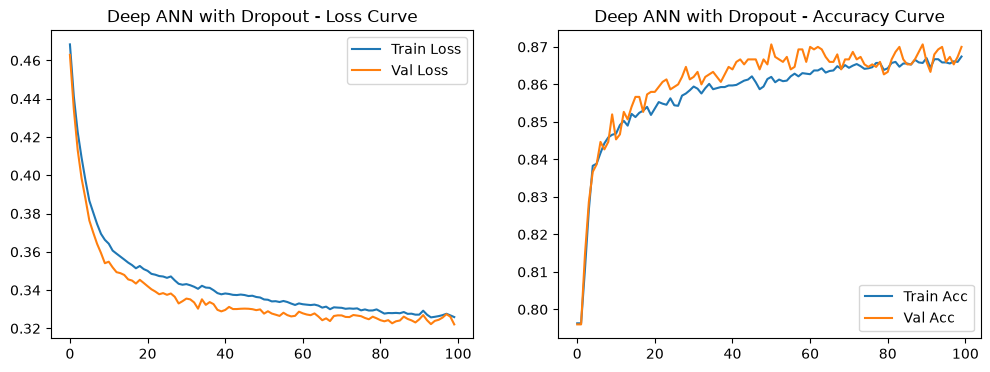

In [16]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
history_deep = train_model(model_deep, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)
plot_history(history_deep, "Deep ANN with Dropout")

In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
model_deep.eval()
with torch.no_grad():
    deep_logits = model_deep(X_test_t)
    deep_probs = torch.sigmoid(deep_logits).numpy().flatten()
    deep_preds = (deep_probs >= 0.5).astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [18]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).
# Hitung bobot = jumlah mayoritas (0) / jumlah minoritas (1)
pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()
pos_weight = torch.tensor([pos_weight_val], dtype=torch.float32)
print(f"Pos Weight Calculated: {pos_weight.item():.2f}")

# Reset arsitektur model
model_weighted = DeepANN(input_dim) 
history_weighted = train_model(model_weighted, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, epochs=100, pos_weight=pos_weight)

Pos Weight Calculated: 3.91


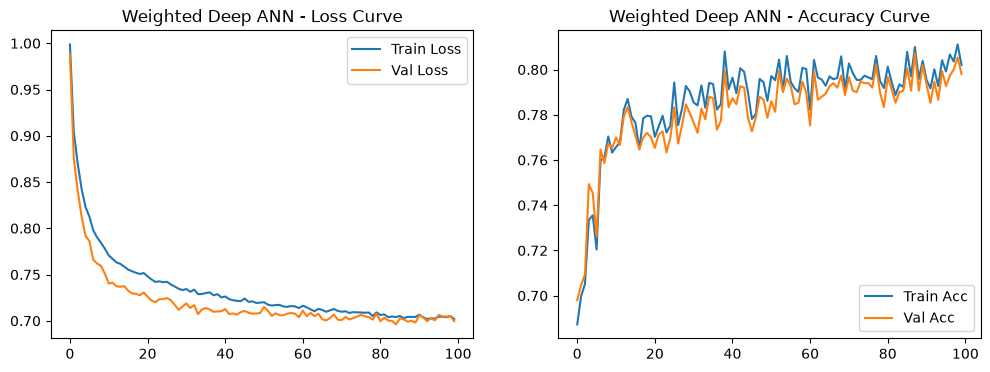

In [19]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
plot_history(history_weighted, "Weighted Deep ANN")

model_weighted.eval()
with torch.no_grad():
    weighted_logits = model_weighted(X_test_t)
    weighted_probs = torch.sigmoid(weighted_logits).numpy().flatten()
    weighted_preds = (weighted_probs >= 0.5).astype(int)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
models_preds = {
    'Logistic Regression': (lr_preds, lr_probs),
    'Simple ANN': (simple_preds, simple_probs),
    'Deep ANN (Dropout)': (deep_preds, deep_probs),
    'Weighted Deep ANN': (weighted_preds, weighted_probs)
}

results = []
for name, (preds, _) in models_preds.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.815333,0.645833,0.203279,0.309227
1,Simple ANN,0.868000,0.777202,0.491803,0.602410
2,Deep ANN (Dropout),0.868667,0.800000,0.472131,0.593814
3,Weighted Deep ANN,0.796000,0.498947,0.777049,0.607692


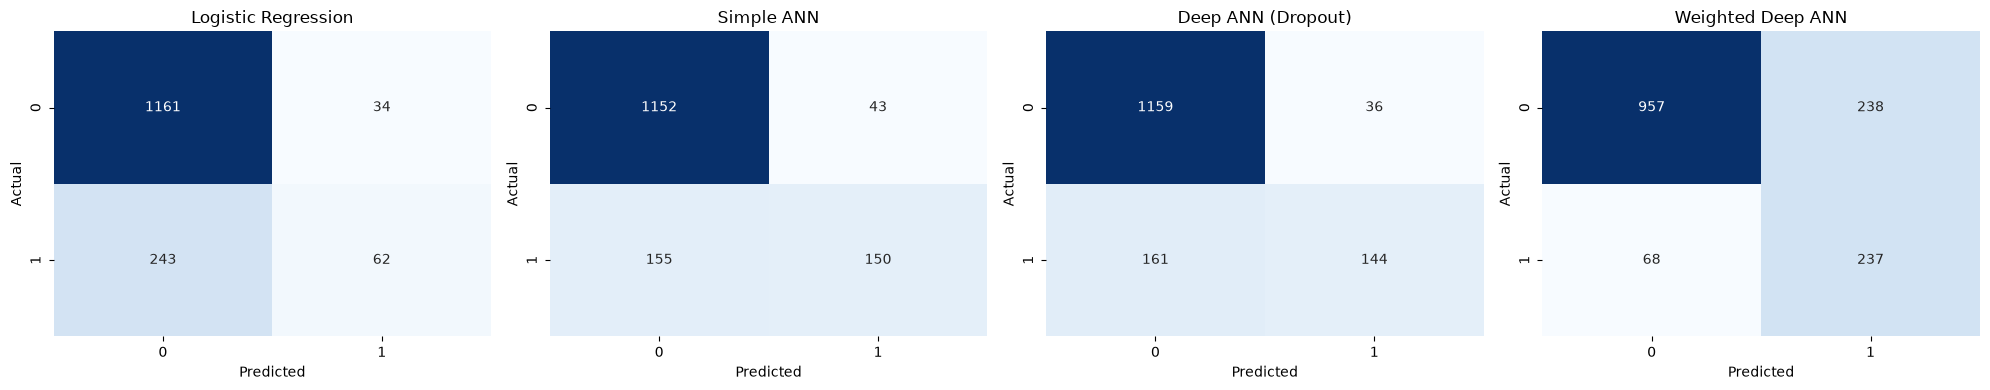

In [21]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, (name, (preds, _)) in enumerate(models_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
plt.tight_layout()
plt.show()

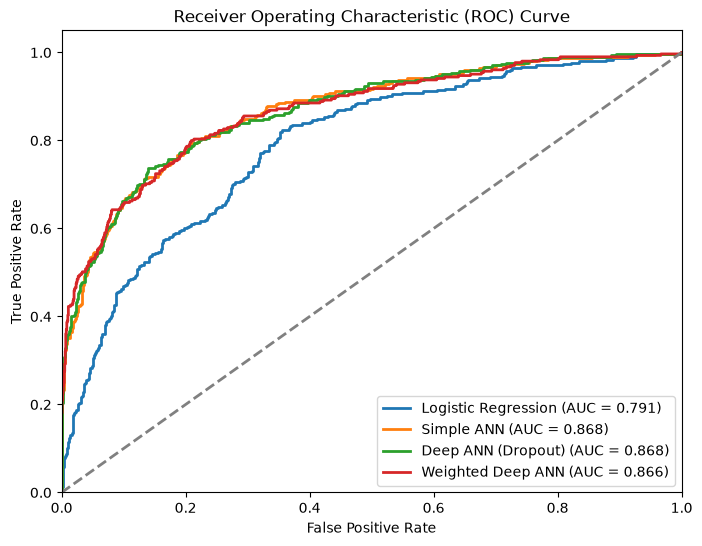

In [22]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(8, 6))
for name, (_, probs) in models_preds.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# 5. Analisis


**Logistic Regression:**

Model dasar ini menghasilkan tingkat Accuracy sebesar 0.815333 atau 81.5%. Tapi, model ini sangat bias terhadap kelas mayoritas (Tidak Churn), dibuktikan dengan metrik Recall kelas *churn* yang sangat rendah di angka 0.203279.

Berdasarkan hasil pada Confusion Matrix, model ini hanya berhasil mendeteksi 62 pelanggan yang benar-benar *churn* (True Positive) Sebaliknya, 243 pelanggan *churn* lainnya luput dari deteksi model (False Negative).

---

**Simple ANN dan Deep ANN (Dropout):**

Kedua arsitektur ini menunjukkan peningkatan signifikan dibandingkan *baseline*, dengan Accuracy mencapai 0.868000 dan 0.868667. Kemampuan model dalam mendeteksi *churn* juga meningkat dengan jumlah True Positive mencapai 150 untuk Simple ANN dan 144 untuk Deep ANN.

Penambahan lapisan *Dropout* pada Deep ANN mampu menaikkan nilai Precision menjadi 0.800000 dibandingkan Simple ANN yang bernilai 0.777202. Tapi, penambahan ini membuat Recall sedikit menurun dari 0.491803 menjadi 0.472131.

Kedua model ANN ini sama-sama menghasilkan nilai Area Under Curve (AUC) tertinggi yaitu 0.868.

Kelemahan utama dari kedua model ini adalah angka False Negative yang masih tinggi (155 dan 161), yang berarti model melewatkan lebih dari separuh pelanggan yang berniat pergi.

---

**Penanganan Data Imbalanced (Weighted Deep ANN):**

Penerapan bobot kelas (*class weight*) pada fungsi *loss* terbukti menjadi solusi paling efektif untuk mendongkrak sensitivitas model.

Metrik Recall melonjak sangat drastis ke angka 0.777049.Model ini berhasil mengidentifikasi 237 pelanggan *churn* (True Positive).
Angka False Negative (pelanggan *churn* yang terlewat) juga berhasil ditekan secara dramatis menjadi hanya 68.

Sebagai *trade-off* atau kompromi matematis dari penalti kelas minoritas ini, nilai Precision menurun menjadi 0.498947. Terdapat peningkatan jumlah prediksi positif yang salah (False Positive) sebanyak 238 kasus.

Meskipun nilai *Accuracy* secara umum turun menjadi 0.796000, performa model secara keseluruhan tetap terjaga dengan baik yang dibuktikan dengan skor AUC kompetitif di angka 0.866.





# 6. Kesimpulan dan Saran

### Teks untuk Cell 37 (Kesimpulan dan Saran)

**Kesimpulan**

Dalam penyelesaian kasus prediksi *Customer Churn*, metrik *Accuracy* saja terbukti sangat menyesatkan akibat ketidakseimbangan kelas (*imbalanced data*). Model seperti Simple ANN dan Deep ANN memiliki *Accuracy* paling superior yaitu sekitar 86.8%. Akan tetapi, model-model tersebut masih gagal mendeteksi sebagian besar target utama karena metrik *Recall*-nya berada di bawah 50%.


Di dunia nyata (industri perbankan), kerugian finansial dari satu pelanggan yang luput terdeteksi dan akhirnya pergi (*False Negative*) jauh lebih membebani perusahaan daripada memberikan bonus retensi kepada pelanggan yang sebenarnya tidak berniat pergi (*False Positive*).


Oleh karena itu, **Weighted Deep ANN** diakui sebagai model yang paling sesuai dan optimal untuk penyelesaian *task* ini. Model ini mampu memberikan nilai *Recall* paling tinggi (77.7%). Selain itu, model tersebut juga paling sukses menekan kesalahan fatal *False Negative* ke level terendah yaitu 68.



**Saran Eksperimen Selanjutnya**

* Threshold Tuning
* Eksplorasi Teknik Resampling (seperti SMOTE)